---
title: "The Variational Method and WKB — Level 2"
short_title: "09 Variational Method & WKB"
numbering:
  heading_2: true
  equation: true
---

# The Variational Method and WKB

:::{seealso} Math for this topic
- [Q-M5: Asymptotics, WKB and Bessel functions](../math/05-asymptotics-wkb-bessel.ipynb)
- [M5: Calculus of variations](../../level2-book/math/05-calculus-of-variations.ipynb)
- [M4: Linear ODEs, Fourier series and transforms](../../level2-book/math/04-linear-odes-fourier.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Griffiths QM, ch. 7–8** | **Trial wave functions, WKB quantization and tunneling** |
| 3 | Sakurai, ch. 2 and 5 | Connection formulas, Bohr–Sommerfeld quantization, the semiclassical limit |

The new skill at this level: getting good energies without solving the Schrödinger equation: bounding the ground state with a guess, or using slowly varying waves

Math for this topic: Q-M5 (asymptotics and WKB), mechanics M5 (calculus of variations) and mechanics M4 (second-order ODEs).
:::

Workbook example ladder: a trial wave function for helium → the WKB tunneling rate → Bohr–Sommerfeld quantization with the Maslov correction. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Time-Dependent Perturbation Theory](10-time-dependent-perturbation.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **The Variational Principle**

   (a) Use the trial function $\psi = Ae^{-b|x|}$ on the harmonic oscillator. Minimize $\langle H\rangle$ over $b$ and compare with $\tfrac12\hbar\omega$.

   (b) Why is the variational energy usually much more accurate than the trial wave function?

2. **Helium, Variationally**

   The best screened charge is $Z_{\text{eff}} = 27/16 \approx 1.69$, which is less than 2. What does that mean physically? How does the resulting energy compare with the measured $-79.0$ eV?

3. **WKB in Practice**

   Quantization reads $\int p\,dx = (n + c)\pi\hbar$. Find the offset $c$ for:

   (a) two soft turning points

   (b) one hard wall and one soft turning point (the bouncing ball)

   (c) two hard walls. Check this case against the infinite well.

4. **WKB in Practice**: alpha decay

   (a) Explain why alpha-decay lifetimes depend so steeply on the alpha energy.

   (b) Two alpha emitters have tunneling exponents $2\gamma = 80$ and $2\gamma = 40$. Roughly how do their decay rates compare?

:::{dropdown} Answers
1. (a) $\langle T\rangle = \dfrac{\hbar^2b^2}{2m}$ and $\langle V\rangle = \dfrac{m\omega^2}{4b^2}$. The minimum is at $b^2 = m\omega/(\sqrt2\,\hbar)$, giving $\langle H\rangle = \dfrac{\hbar\omega}{\sqrt2} \approx 0.71\hbar\omega$, above $0.5\hbar\omega$ as it must be.

   (b) An error of order $\epsilon$ in $\psi$ gives an error of order $\epsilon^2$ in $\langle H\rangle$, because $\langle H\rangle$ is stationary at the true ground state.

2. Each electron partly screens the nucleus from the other. The result is $-77.5$ eV, within 2% of the measured value and above it, as an upper bound must be.

3. (a) $c = \tfrac12$.

   (b) $c = \tfrac34$ (that is, $n - \tfrac14$ with $n$ starting at 1).

   (c) $c = 0$ (with $n$ starting at 1), which reproduces the infinite well exactly.

4. (a) $T \approx e^{-2\gamma}$ with $2\gamma \propto Z/\sqrt{E}$ (Gamow factor). A small change in $E$ changes the exponent by many units.

   (b) The rates differ by about $e^{40} \approx 10^{17}$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Variational Principle

:::{prf:theorem} Variational principle
:label: thm-variational

For any normalized state $|\psi\rangle$,

$$
E_{\text{gs}}\le\langle\psi|\hat H|\psi\rangle .
$$ (eq-variational)
:::

:::{prf:proof}
:class: dropdown

Expand $|\psi\rangle = \sum c_n|\psi_n\rangle$ in the (unknown) eigenstates of $\hat H$, with $\sum|c_n|^2 = 1$. Then $\langle\hat H\rangle = \sum|c_n|^2E_n\ge E_{\text{gs}}\sum|c_n|^2 = E_{\text{gs}}$.
:::

So guess a **trial wave function** with adjustable parameters, compute $\langle H\rangle$, and minimize over the parameters. The minimum is an upper bound on the ground-state energy, and usually a good one: an error of order $\epsilon$ in the wave function produces an error of order $\epsilon^2$ in the energy, because $\langle H\rangle$ is stationary at the true eigenstate (mechanics M5's idea of a stationary functional, applied to $\psi$).

::::{prf:example} A Gaussian guess for the delta well
:label: ex-variational-delta

Use $\psi = Ae^{-bx^2}$ for $V = -\alpha\delta(x)$, whose exact ground state is $-m\alpha^2/2\hbar^2$ (topic 2).

:::{dropdown} Solution
With $A = (2b/\pi)^{1/4}$: $\langle T\rangle = \hbar^2b/2m$ and $\langle V\rangle = -\alpha|\psi(0)|^2 = -\alpha\sqrt{2b/\pi}$. Minimizing $\langle H\rangle(b)$ gives $b = 2m^2\alpha^2/\pi\hbar^4$ and $\langle H\rangle_{\min} = -m\alpha^2/\pi\hbar^2$, which is $2/\pi = 0.64$ of the exact energy: above it, as promised. A Gaussian is a poor shape for a cusp, and the bound reflects that.
:::
::::

In [2]:
bb, m, al, hb = sp.symbols("b m alpha hbar", positive=True)
H_b = hb**2 * bb / (2 * m) - al * sp.sqrt(2 * bb / sp.pi)
bmin = sp.solve(sp.diff(H_b, bb), bb)[0]
Emin = sp.simplify(H_b.subs(bb, bmin))
display(Math(r"b_{\min} = " + sp.latex(bmin) + r",\qquad \langle H\rangle_{\min} = " + sp.latex(Emin) + r",\qquad \frac{\langle H\rangle_{\min}}{E_{\rm exact}} = " + sp.latex(sp.simplify(Emin / (-m * al**2 / (2 * hb**2))))))

<IPython.core.display.Math object>

## Helium, Variationally

Topic 7 found $-74.8$ eV for helium by averaging the repulsion over two unscreened $1s$ orbitals. But each electron partly shields the nucleus from the other, so try hydrogen-like orbitals with an **effective charge** $Z$ as the variational parameter, $\psi = \frac{Z^3}{\pi a^3}e^{-Z(r_1 + r_2)/a}$. The expectation values are hydrogen results rescaled by $Z$ (in units of $E_1 = -13.6$ eV, so $-E_1 = 13.6$ eV):

$$
\langle T\rangle = 2Z^2(-E_1),\qquad
\langle V_{ne}\rangle = -4\cdot2Z(-E_1),\qquad
\langle V_{ee}\rangle = \tfrac54Z(-E_1) ,
$$

the $2$ in $V_{ne}$ being the actual nuclear charge. So

$$
\langle H\rangle(Z) = \left(2Z^2 - \tfrac{27}{4}Z\right)(13.6\text{ eV}) .
$$ (eq-helium-variational)

In [3]:
Z = sp.symbols("Z", positive=True)
H_Z = (2 * Z**2 - sp.Rational(27, 4) * Z) * 13.606
Zbest = sp.solve(sp.diff(2 * Z**2 - sp.Rational(27, 4) * Z, Z), Z)[0]
display(Math(r"Z_{\rm best} = " + sp.latex(sp.nsimplify(Zbest)) + rf" = {float(Zbest):.4f},\qquad \langle H\rangle_{{\min}} = {float(H_Z.subs(Z, Zbest)):.2f}\ \text{{eV}}\quad(\text{{measured }} -79.01)"))

<IPython.core.display.Math object>

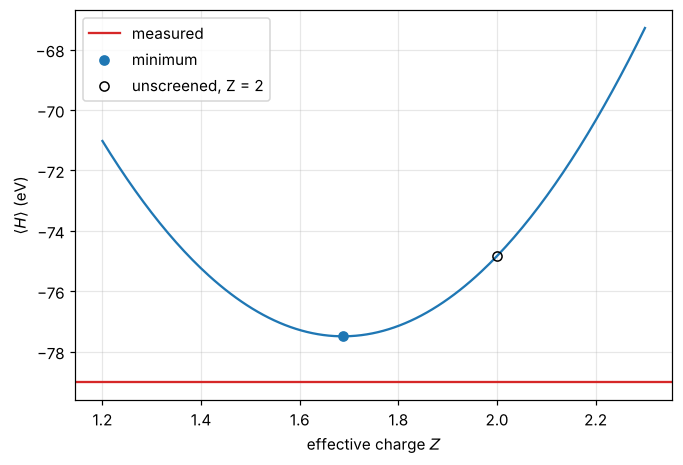

In [4]:
#| label: fig-helium-variational
#| caption: "The variational energy of helium as a function of the effective charge Z in the trial function. The minimum, −77.5 eV at Z = 27/16 ≈ 1.69, lies above the measured −79.0 eV (red), as it must, and beats the unscreened Z = 2 estimate (−74.8 eV, open circle)."
Zs = np.linspace(1.2, 2.3, 200)
E = (2 * Zs**2 - 27 / 4 * Zs) * 13.606
fig, ax = plt.subplots()
ax.plot(Zs, E); ax.axhline(-79.01, color="tab:red", label="measured")
ax.plot(27 / 16, (2 * (27 / 16)**2 - 27 / 4 * 27 / 16) * 13.606, "o", color="tab:blue", label="minimum")
ax.plot(2, (8 - 13.5) * 13.606, "o", mfc="none", color="k", label="unscreened, Z = 2")
ax.set_xlabel("effective charge $Z$"); ax.set_ylabel("$\\langle H\\rangle$ (eV)"); ax.legend(); plt.show()

The best $Z$, 1.69, says each electron sees the nucleus partly screened by the other. Adding more parameters (correlation between the electrons, such as a factor depending on $|\vec r_1 - \vec r_2|$) drives the energy down to the measured value; Hylleraas did this by hand in 1929, and modern calculations agree with experiment to many digits.

## WKB in Practice

Q-M5 derived the WKB approximation. Its two main uses are quantization and tunneling.

**Quantization.** For a well with two smooth turning points,

$$
\oint p\,dx = 2\int_a^bp\,dx = \left(n + \tfrac12\right)h .
$$ (eq-bohr-sommerfeld)

If one wall is vertical (infinite), the phase there is different and the $\tfrac12$ becomes $\tfrac34$; two vertical walls give an integer. These offsets are the **Maslov indices** that Level 3 formalizes.

::::{prf:example} The quantum bouncing ball
:label: ex-bouncing-ball

A particle bounces on a hard floor in uniform gravity, $V = mgx$ for $x > 0$, infinite for $x < 0$. Find the WKB energies.

:::{dropdown} Solution
One hard wall and one soft turning point at $x_t = E/mg$: $\int_0^{x_t}\sqrt{2m(E - mgx)}\,dx = \left(n - \tfrac14\right)\pi\hbar$ with $n = 1, 2, \ldots$ The integral is $\tfrac23\sqrt{2m}E^{3/2}/mg$, so

$$
E_n = \left(\frac{9\pi^2}{8}\right)^{1/3}\left(mg^2\hbar^2\right)^{1/3}\left(n - \tfrac14\right)^{2/3} .
$$

The exact energies are set by the zeros of the Airy function. The code compares them: WKB is within 1% from the ground state on. Neutrons bouncing on a mirror show these levels (energies of a few peV).
:::
::::

In [5]:
from scipy.special import ai_zeros
n = np.arange(1, 9)
E_exact = -ai_zeros(8)[0]                       # in units of (m g^2 hbar^2 / 2)^(1/3)
E_wkb = (3 * np.pi / 2 * (n - 0.25))**(2 / 3)    # same units
display(Math(r"E_n^{\rm exact} = " + ",\\ ".join(f"{e:.4f}" for e in E_exact)))
display(Math(r"E_n^{\rm WKB} = " + ",\\ ".join(f"{e:.4f}" for e in E_wkb)))
display(Math(r"\text{relative error} = " + ",\\ ".join(f"{abs(w - e) / e:.1e}" for w, e in zip(E_wkb, E_exact))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Tunneling.** Through a barrier between turning points $x_1$ and $x_2$,

$$
T\approx e^{-2\gamma},\qquad\gamma = \frac1\hbar\int_{x_1}^{x_2}\sqrt{2m(V(x) - E)}\,dx .
$$ (eq-gamow-factor)

### Alpha decay

Gamow (1928) modeled an alpha particle as trapped inside a nucleus of radius $r_1$ by the Coulomb barrier $V = 2Ze^2/4\pi\epsilon_0r$ of the daughter nucleus (charge $Ze$). The outer turning point $r_2$ is where $V = E$. Evaluating {eq}`eq-gamow-factor` for $r_1\ll r_2$ gives approximately

$$
\gamma\approx\frac{\pi}{\hbar}\frac{2Ze^2}{4\pi\epsilon_0}\sqrt{\frac{m}{2E}} - \frac{4}{\hbar}\sqrt{\frac{2Ze^2mr_1}{4\pi\epsilon_0}} .
$$ (eq-gamow-alpha)

The alpha hits the barrier at a rate $v/2r_1$, so the lifetime is $\tau\approx(2r_1/v)e^{2\gamma}$, and $\ln\tau$ is linear in $1/\sqrt E$: the empirical Geiger–Nuttall law. Because $E$ sits in an exponent, a factor of two in energy changes the lifetime by more than twenty orders of magnitude.

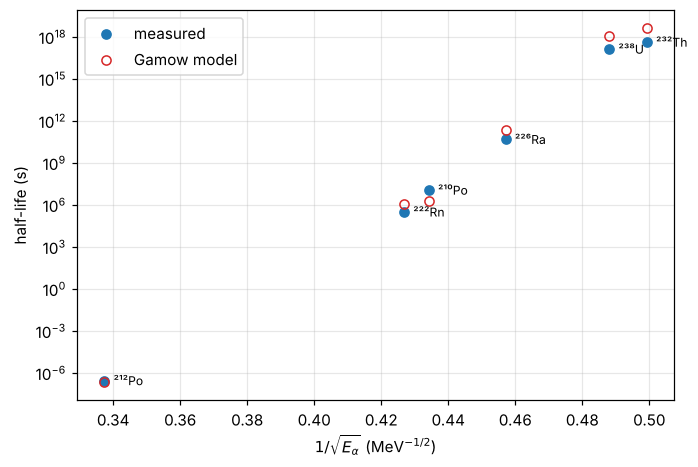

In [6]:
#| label: fig-alpha-decay
#| caption: "Alpha-decay half-lives from the Gamow model (open circles; full WKB integral starting where the alpha touches the daughter, r = 1.2(A_d^(1/3) + 4^(1/3)) fm) compared with measured values (filled) for six even-even emitters, plotted against 1/√E. Across 24 orders of magnitude in half-life the model tracks the data to within about a factor of 10, and both follow the straight Geiger–Nuttall line."
emitters = [  # name, Z_parent, A_parent, Q (MeV), measured half-life (s)
    ("²¹²Po", 84, 212, 8.954, 2.99e-7), ("²²²Rn", 86, 222, 5.590, 3.30e5), ("²¹⁰Po", 84, 210, 5.407, 1.20e7),
    ("²²⁶Ra", 88, 226, 4.871, 5.05e10), ("²³⁸U", 92, 238, 4.270, 1.41e17), ("²³²Th", 90, 232, 4.082, 4.42e17)]
e2 = 1.43996       # e^2/(4 pi eps0) in MeV fm
hbarc = 197.327    # MeV fm
mac2 = 3727.38     # alpha rest energy, MeV
def gamow_halflife(Zp, A, Q):
    Zd = Zp - 2
    E = Q * (A - 4) / A                       # alpha kinetic energy
    r1 = 1.2 * ((A - 4)**(1 / 3) + 4**(1 / 3))   # alpha just touching the daughter nucleus
    r2 = 2 * Zd * e2 / E
    gam, _ = quad(lambda r: np.sqrt(2 * mac2 * (2 * Zd * e2 / r - E)) / hbarc, r1, r2)
    v = np.sqrt(2 * E / mac2) * 2.998e23   # fm/s
    tau = 2 * r1 / v * np.exp(2 * gam)
    return E, tau * np.log(2)
fig, ax = plt.subplots()
for name, Zp, A, Q, t_meas in emitters:
    E, t_g = gamow_halflife(Zp, A, Q)
    ax.semilogy(1 / np.sqrt(E), t_meas, "o", color="tab:blue"); ax.semilogy(1 / np.sqrt(E), t_g, "o", mfc="none", color="tab:red")
    ax.annotate(name, (1 / np.sqrt(E), t_meas), (6, -3), textcoords="offset points", fontsize=8)
ax.plot([], [], "o", color="tab:blue", label="measured"); ax.plot([], [], "o", mfc="none", color="tab:red", label="Gamow model")
ax.set_xlabel("$1/\\sqrt{E_\\alpha}$ (MeV$^{-1/2}$)"); ax.set_ylabel("half-life (s)"); ax.legend(); plt.show()

## Looking Ahead to Level 3

The connection formulas that produce the $\tfrac12$ in {eq}`eq-bohr-sommerfeld` generalize to many dimensions as the Einstein–Brillouin–Keller rule, $\oint p_i\,dq_i = (n_i + \mu_i/4)h$ with Maslov indices $\mu_i$ counting turning points and reflections. Sakurai connects WKB to the path integral: in the limit $\hbar\to0$ the sum over paths is dominated by the classical path and its neighbors (stationary phase), and the semiclassical wave function is $e^{iS_{\text{cl}}/\hbar}$, with $S_{\text{cl}}$ the action of mechanics M5.

## Exercises

### Exercises

1. Use $\psi = Ae^{-bx^2}$ on the harmonic oscillator. What do you get, and why?
2. Use a triangular trial function $\psi\propto\max(0, a/2 - |x - a/2|)$ for the infinite well (width $a$). Compare $\langle H\rangle$ with $E_1$.
3. Show that the WKB rule {eq}`eq-bohr-sommerfeld` gives hydrogen's radial energies exactly if you replace $\ell(\ell+1)$ by $(\ell + \tfrac12)^2$ (Langer's correction). (Just set up the integral; the result is known.)
4. Estimate the probability that an electron with 1 eV tunnels through a 2 eV, 1 nm barrier using {eq}`eq-gamow-factor`, and compare with topic 2's exact result.
5. Use {eq}`eq-gamow-alpha` to explain why ²³⁸U (4.27 MeV) lives $10^{24}$ times longer than ²¹²Po (8.95 MeV), roughly.

:::{dropdown} Hints
1. The exact ground state is a Gaussian.
2. $\psi'$ is a constant on each half and $\psi''$ is a delta function at the peak.
3. $\int\sqrt{2m[E + e^2/4\pi\epsilon_0r - \hbar^2(\ell + \frac12)^2/2mr^2]}\,dr = (n_r + \tfrac12)\pi\hbar$.
4. $\gamma = \kappa a$ for a flat barrier.
5. The dominant term in $2\gamma$ is proportional to $Z/\sqrt E$.
:::

:::{dropdown} Answers
1. The minimum is exactly $\tfrac12\hbar\omega$ at $b = m\omega/2\hbar$: the trial family contains the true ground state.
2. $\langle H\rangle = 12\hbar^2/2ma^2 = 1.216E_1$: 22% high, despite the kink.
3. The integral is a standard one; it gives $E = -13.6\text{ eV}/(n_r + \ell + 1)^2$, exactly Bohr.
4. $T\approx e^{-2\kappa a} = e^{-14.5}\approx5\times10^{-7}$; topic 2's exact $1.8\times10^{-6}$ includes a prefactor of about 4.
5. $2\gamma\approx(2\pi\cdot2Z e^2/4\pi\epsilon_0\hbar)\sqrt{m/2E}$; with $Z\approx90$ the difference in $1/\sqrt E$ between 4.3 and 8.9 MeV changes $2\gamma$ by about 55, i.e. $e^{55}\approx10^{24}$.
:::

## Summary

- $\langle\psi|\hat H|\psi\rangle\ge E_{\text{gs}}$ for any normalized $\psi$; minimizing over parameters gives an upper bound with second-order error.
- Helium with screened charge $Z = 27/16$: $-77.5$ eV, versus $-79.0$ eV measured.
- WKB quantization: $\oint p\,dx = (n + \tfrac12)h$ for soft turning points, with different offsets for hard walls.
- WKB tunneling $T\approx e^{-2\gamma}$ explains alpha decay and the Geiger–Nuttall law over two dozen orders of magnitude.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.